# Prediksi Biaya Asuransi Kesehatan (Medical Insurance Cost)
Notebook ini menyusun alur machine learning dari awal sampai akhir: data collecting, data loading, cleaning dan transformation, EDA/ExDA, data splitting, modelling, hingga evaluasi dan penyimpanan model. Urutannya mengikuti materi dosen, tetapi disesuaikan dengan dataset insurance.

Kolom pada dataset: `age` (usia), `sex` (jenis kelamin), `bmi` (indeks massa tubuh), `children` (jumlah tanggungan), `smoker` (perokok atau bukan), `region` (wilayah tinggal di AS), dan `charges` (biaya asuransi, **target**).

## 1. Pengenalan Data dan Machine Learning
Target `charges` berupa angka kontinu, sehingga kasus ini termasuk **supervised learning** jenis **regresi**. Seandainya targetnya kategorikal (misalnya kelas biaya rendah/sedang/tinggi), algoritma yang dipakai berganti menjadi klasifikasi.

Alur kerja (workflow): Data Collecting → Data Loading → Data Cleaning → EDA → Data Processing → Data Splitting → Modelling → Evaluasi → Penyimpanan model.

**Penjelasan.** Cell ini menyiapkan seluruh pustaka yang dipakai sepanjang notebook. `pandas` dan `numpy` dipakai untuk mengolah data dan menghitung angka, sedangkan `matplotlib` dan `seaborn` dipakai untuk membuat grafik. `warnings.filterwarnings('ignore')` menyembunyikan peringatan yang tidak memengaruhi hasil supaya keluaran notebook lebih bersih, dan `sns.set(style='whitegrid')` menetapkan tema grid putih untuk semua grafik.

Cell ini tidak menghasilkan keluaran apa pun karena hanya memuat pustaka ke memori. Jika muncul error `ModuleNotFoundError`, artinya ada pustaka yang belum terpasang di lingkungan kerja dan perlu di-install terlebih dahulu.

In [1]:
# Library utama untuk data science dan machine learning
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set(style='whitegrid')
%matplotlib inline

## 2. Data Collecting
Dataset diambil dari sumber terbuka (Medical Cost Personal Datasets, tersedia di Kaggle dan GitHub). Jika tidak ada koneksi internet, gunakan file `insurance.csv` yang sudah diunduh secara lokal.

**Penjelasan.** Ini adalah tahap *data collecting*: mengambil data dari sumber terbuka. Alamat dataset disimpan di `URL_DATA`, lalu `pd.read_csv` membaca file CSV tersebut langsung dari internet menjadi sebuah tabel (DataFrame) bernama `insurance`. Blok `try-except` dipakai sebagai pengaman: jika pengambilan dari internet gagal, program otomatis membaca file `insurance.csv` yang sudah diunduh dan disimpan secara lokal.

Baris `print` terakhir menampilkan ukuran data dalam format (jumlah baris, jumlah kolom). Hasil `(1338, 7)` menunjukkan terdapat 1.338 pemegang polis dengan 7 kolom, sehingga dapat dipastikan data berhasil dikumpulkan secara utuh.

In [2]:
# Sumber data terbuka (versi mirror di GitHub)
URL_DATA = ("https://raw.githubusercontent.com/stedy/"
            "Machine-Learning-with-R-datasets/master/insurance.csv")

try:
    insurance = pd.read_csv(URL_DATA)                 # coba ambil dari internet
except Exception:
    # cadangan: file lokal (Colab)
    insurance = pd.read_csv("/content/insurance.csv")

print("Data berhasil dikumpulkan:", insurance.shape)

Data berhasil dikumpulkan: (1338, 7)


## 3. Data Loading
Memuat data dan melihat sekilas isinya. Data asli disimpan di `insurance`, sedangkan proses selanjutnya memakai salinan `df` agar data asli tetap utuh.

**Penjelasan.** Tahap *data loading* ini membuat salinan data kerja bernama `df` memakai `.copy()`. Salinan diperlukan agar semua proses pembersihan berikutnya hanya mengubah `df`, sementara data asli di `insurance` tetap utuh dan bisa dipakai kembali sebagai pembanding jika terjadi kesalahan.

`display(df.head())` menampilkan lima baris pertama sehingga kita bisa melihat sekilas isi dan format tiap kolom, sedangkan `df.shape` memastikan jumlah baris dan kolom sama dengan data asli.

In [3]:
# Salinan kerja, data asli tidak diubah
df = insurance.copy()

# Menampilkan 5 baris pertama dan ukuran data (baris, kolom)
display(df.head())
print("Ukuran data:", df.shape)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Ukuran data: (1338, 7)


## 4. Data Cleaning dan Transformation

### 4.1 Identifikasi informasi dataset

**Penjelasan.** Metode `info()` memberikan ringkasan struktur dataset: jumlah baris, nama kolom, jumlah nilai yang tidak kosong (*non-null*), dan tipe data setiap kolom. Pemeriksaan ini penting untuk memastikan tidak ada tipe data yang keliru, misalnya angka yang terbaca sebagai teks, karena kesalahan tipe akan menyulitkan tahap preprocessing.

Pada keluaran terlihat semua kolom memiliki 1.338 nilai non-null, yang berarti belum ada indikasi data kosong. Kolom `age` dan `children` bertipe integer, `bmi` dan `charges` bertipe float, sedangkan `sex`, `smoker`, dan `region` bertipe teks sehingga nanti perlu diubah menjadi angka.

In [4]:
# Ringkasan tipe data dan jumlah nilai non-null tiap kolom
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


**Penjelasan.** `describe(include="all")` menghasilkan statistik deskriptif untuk semua kolom, baik numerik maupun kategorikal. Untuk kolom numerik ditampilkan rata-rata, simpangan baku, nilai minimum, kuartil, dan maksimum; untuk kolom kategorikal ditampilkan jumlah kategori unik, kategori yang paling sering muncul, dan frekuensinya.

Dari tabel ini kita bisa membaca sebaran awal data dan mendeteksi kejanggalan. Misalnya, pada `charges` rata-rata jauh lebih besar daripada median dan nilai maksimumnya sangat tinggi, yang menandakan distribusi condong ke kanan dan kemungkinan adanya nilai ekstrem.

In [5]:
# Statistik deskriptif seluruh kolom (numerik dan kategorikal)
df.describe(include="all")

,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


### 4.2 Mengatasi missing value

**Penjelasan.** Kode ini menghitung jumlah nilai kosong (*missing value*) pada setiap kolom dengan `isnull().sum()`. Memeriksa missing value wajib dilakukan karena sebagian besar algoritma tidak dapat memproses data yang kosong dan akan menghasilkan error atau prediksi yang kurang akurat.

Percabangan `if-else` menampilkan kolom yang memiliki nilai kosong, atau pesan "Tidak ada missing value" jika data sudah lengkap. Pada dataset ini hasilnya adalah tidak ada nilai kosong.

In [6]:
# Jumlah missing value per kolom
missing_values = df.isnull().sum()
if missing_values.sum() > 0:
    print(missing_values[missing_values > 0])
else:
    print("Tidak ada missing value")

Tidak ada missing value


**Penjelasan.** Kolom dipisahkan menjadi dua kelompok berdasarkan ambang 75% dari jumlah baris. Kolom dengan jumlah missing value di bawah ambang masuk ke `less` dan masih layak diperbaiki dengan imputasi, sedangkan kolom yang missing-nya mencapai ambang atau lebih masuk ke `over` karena terlalu banyak kehilangan informasi dan lebih baik dibuang.

Karena dataset ini tidak memiliki missing value, semua kolom masuk ke kelompok `less` dan kelompok `over` kosong. Langkah ini tetap dijalankan agar alur kerja lengkap dan bisa dipakai ulang pada dataset lain.

In [7]:
# Pisahkan kolom berdasarkan batas 75% missing value
batas = 0.75 * len(df)
less = missing_values[missing_values < batas].index
over = missing_values[missing_values >= batas].index
print("Kolom missing < 75%:", list(less))
print("Kolom missing >= 75%:", list(over))

Kolom missing < 75%: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']
Kolom missing >= 75%: []


**Penjelasan.** Cell ini menangani missing value sesuai tipe datanya. Kolom numerik diisi dengan **median** karena median tidak terpengaruh nilai ekstrem, sedangkan kolom kategorikal diisi dengan **modus** (nilai yang paling sering muncul) karena rata-rata atau median tidak berlaku untuk teks. Kolom dari kelompok `over` dibuang dengan `drop(columns=over)`.

Bagian akhir memverifikasi ulang jumlah missing value. Hasil `Sisa missing value: 0` menegaskan bahwa data sudah lengkap. Karena sebelumnya memang tidak ada nilai kosong, proses imputasi tidak mengubah isi data.

In [8]:
# Numerik diisi median, kategorikal diisi modus
numeric_features = df[less].select_dtypes(include=['number']).columns
df[numeric_features] = df[numeric_features].fillna(df[numeric_features].median())

kategorikal_features = df[less].select_dtypes(exclude=['number']).columns
for column in kategorikal_features:
    df[column] = df[column].fillna(df[column].mode()[0])

# Hapus kolom dengan missing value berlebih (pada dataset ini tidak ada)
df = df.drop(columns=over)

# Verifikasi ulang
missing_values = df.isnull().sum()
print("Sisa missing value:", missing_values.sum())

Sisa missing value: 0


### 4.3 Mengatasi outliers
Outlier dideteksi dengan boxplot dan metode IQR. Penghapusan outlier hanya dilakukan pada **fitur** (`age`, `bmi`, `children`). Kolom target `charges` sengaja tidak dihapus, karena biaya yang tinggi di sini adalah data asli (umumnya milik perokok), bukan kesalahan input.

**Penjelasan.** Box plot dibuat untuk setiap kolom numerik guna mendeteksi *outlier* secara visual. Kotak menunjukkan rentang kuartil pertama sampai ketiga, garis di dalamnya adalah median, dan titik-titik di luar garis whisker adalah nilai yang dianggap outlier. Perulangan `for` membuat satu grafik untuk setiap kolom numerik.

Hasilnya, `age` dan `children` tidak memiliki outlier, `bmi` memiliki beberapa titik di sisi atas, dan `charges` memiliki cukup banyak titik di sisi atas. Temuan ini menjadi dasar keputusan penanganan outlier pada cell berikutnya.

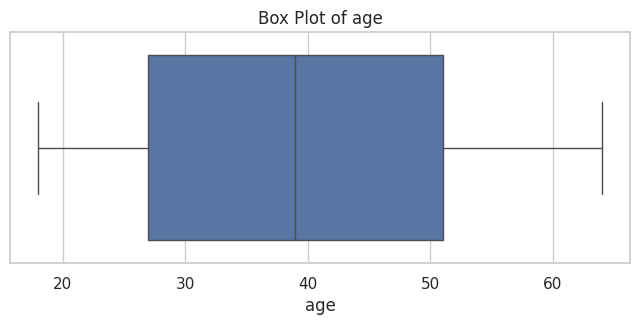

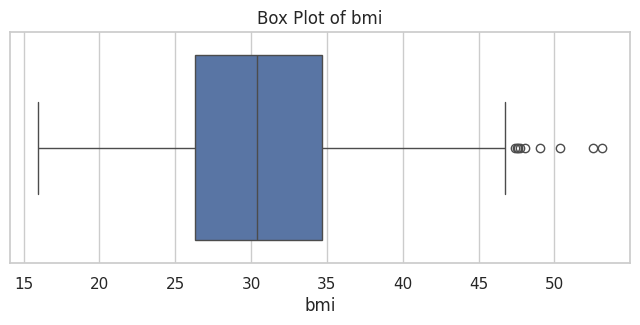

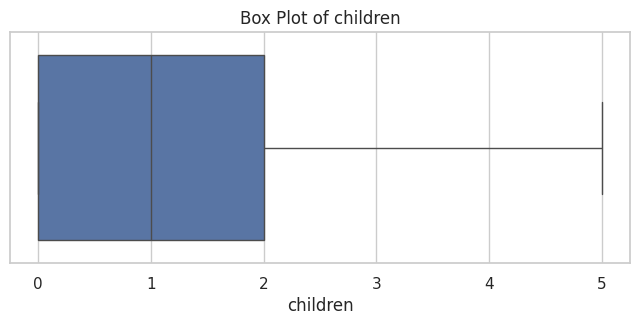

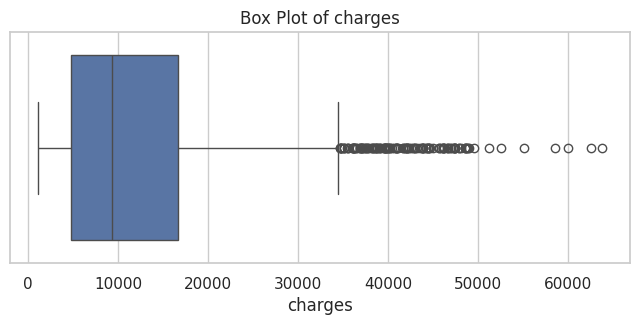

In [9]:
# Boxplot untuk semua kolom numerik
for feature in numeric_features:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

**Penjelasan.** Outlier ditangani dengan metode IQR. Kode menghitung Q1 (persentil ke-25), Q3 (persentil ke-75), dan IQR = Q3 − Q1, lalu menentukan batas bawah (Q1 − 1,5 × IQR) dan batas atas (Q3 + 1,5 × IQR). Baris yang memiliki nilai di luar batas pada salah satu fitur dianggap outlier dan dibuang.

Penghapusan hanya diterapkan pada fitur (`age`, `bmi`, `children`) dan tidak pada target `charges`, karena biaya yang tinggi adalah data asli milik perokok dan menghapusnya akan membuang pola terpenting yang harus dipelajari model. Hasilnya 9 baris dihapus sehingga data tersisa 1.329 baris.

In [10]:
# Fitur yang diperiksa outlier-nya (target 'charges' dikecualikan)
target = 'charges'
fitur_numerik = [c for c in numeric_features if c != target]

# Hitung Q1, Q3, dan IQR
Q1 = df[fitur_numerik].quantile(0.25)
Q3 = df[fitur_numerik].quantile(0.75)
IQR = Q3 - Q1

# Hapus baris yang mengandung outlier pada fitur numerik
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR
condition = ~((df[fitur_numerik] < batas_bawah) |
              (df[fitur_numerik] > batas_atas)).any(axis=1)
print("Baris outlier yang dihapus:", (~condition).sum())
df = df.loc[condition].reset_index(drop=True)
print("Ukuran data sekarang:", df.shape)

Baris outlier yang dihapus: 9
Ukuran data sekarang: (1329, 7)


### 4.4 Menangani duplikasi data

**Penjelasan.** Data duplikat dapat membuat satu pengamatan terhitung lebih dari sekali sehingga membiaskan model. `df.duplicated().sum()` menghitung jumlah baris duplikat, lalu `drop_duplicates()` menghapusnya dan `reset_index` merapikan kembali nomor barisnya.

Pada keluaran terdapat satu baris duplikat yang dihapus, sehingga data tersisa 1.328 baris. Setelah itu disimpan salinan `df_clean`, yaitu data bersih yang belum diskalakan dan belum di-encode, supaya grafik pada tahap EDA tetap memakai nilai asli yang mudah dibaca.

In [11]:
# Identifikasi dan hapus baris duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())
print(df[df.duplicated()])

df = df.drop_duplicates().reset_index(drop=True)
print("Ukuran data setelah menghapus duplikat:", df.shape)

# Simpan versi bersih (belum diskalakan/di-encode) untuk keperluan visualisasi EDA
df_clean = df.copy()

Jumlah baris duplikat: 1
     age   sex    bmi  children smoker     region    charges
577   19  male  30.59         0     no  northwest  1639.5631
Ukuran data setelah menghapus duplikat: (1328, 7)


### 4.5 Standardisasi data
Fitur numerik distandardisasi (mean 0, std 1) dengan `StandardScaler`, sesuai materi dosen. Kolom target `charges` tidak diskalakan supaya hasil prediksi dan nilai error tetap dalam satuan dolar.

**Penjelasan.** Standardisasi mengubah fitur numerik sehingga memiliki rata-rata 0 dan simpangan baku 1 dengan rumus z = (x − rata-rata) / simpangan baku. Hal ini penting karena fitur memiliki skala berbeda (misalnya `age` puluhan sedangkan `children` satuan), dan model berbasis regresi lebih stabil bila skalanya seragam.

`StandardScaler` dipelajari dari data lalu diterapkan dengan `fit_transform` hanya pada fitur numerik. Kolom target `charges` sengaja tidak diskalakan agar hasil prediksi dan nilai error tetap dalam satuan dolar yang mudah ditafsirkan.

In [12]:
from sklearn.preprocessing import StandardScaler

# Standardisasi hanya pada fitur numerik
scaler = StandardScaler()
df[fitur_numerik] = scaler.fit_transform(df[fitur_numerik])

**Penjelasan.** Dua histogram dibuat berdampingan untuk membandingkan distribusi `bmi` sebelum dan sesudah standardisasi. Grafik kiri memakai data bersih `df_clean` (skala asli) dan grafik kanan memakai `df` yang sudah distandardisasi.

Bentuk distribusi kedua grafik sama, yang berubah hanyalah skala sumbu-x: dari kisaran sekitar 16 sampai 47 menjadi berpusat di 0 dengan sebaran sekitar −2 sampai 2. Ini membuktikan standardisasi menyeragamkan skala tanpa merusak pola data.

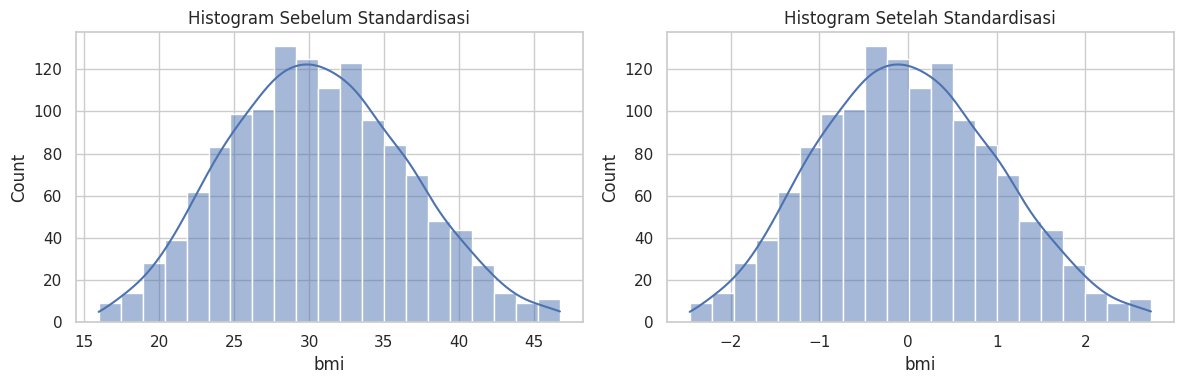

In [13]:
# Perbandingan histogram 'bmi' sebelum dan sesudah standardisasi
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df_clean['bmi'], kde=True)
plt.title("Histogram Sebelum Standardisasi")
plt.subplot(1, 2, 2)
sns.histplot(df['bmi'], kde=True)
plt.title("Histogram Setelah Standardisasi")
plt.tight_layout()
plt.show()

### 4.6 Konversi tipe data (encoding)
Model machine learning hanya menerima angka, sehingga kolom kategorikal (`sex`, `smoker`, `region`) harus di-encode. Berikut dua metode yang diajarkan dosen untuk dibandingkan.

**Penjelasan.** Sebelum melakukan encoding, kolom bertipe non-angka dikumpulkan dengan `select_dtypes(exclude=['number'])`. Tujuannya mengetahui kolom mana saja yang harus diubah menjadi angka karena model machine learning hanya dapat menerima masukan numerik.

Hasilnya adalah tiga kolom kategorikal: `sex`, `smoker`, dan `region`. Daftar ini dipakai oleh cell encoding berikutnya.

In [14]:
# Kolom kategorikal yang perlu di-encode
category_features = df.select_dtypes(exclude=['number']).columns
print(list(category_features))

['sex', 'smoker', 'region']


**Penjelasan.** One-Hot Encoding memecah setiap kolom kategorikal menjadi beberapa kolom biner (0 atau 1), satu kolom untuk setiap kategori, memakai `pd.get_dummies`. Metode ini tidak mengasumsikan urutan antarkategori sehingga cocok untuk data nominal, tetapi menambah jumlah kolom.

Hasil `(1328, 12)` menunjukkan kolom bertambah dari 7 menjadi 12, karena `sex` menjadi 2 kolom, `smoker` 2 kolom, dan `region` 4 kolom. Hasil ini hanya dipakai sebagai perbandingan dengan Label Encoding.

In [15]:
# One-Hot Encoding: tiap kategori menjadi kolom biner baru
df_one_hot = pd.get_dummies(df, columns=category_features)
print("One-Hot Encoding:", df_one_hot.shape)
df_one_hot.head()

One-Hot Encoding: (1328, 12)


,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,-1.440429,-0.445495,-0.908563,16884.92400,True,False,False,True,False,False,False,True
1,-1.511669,0.546068,-0.080442,1725.55230,False,True,True,False,False,False,True,False
2,-0.799261,0.415999,1.575799,4449.46200,False,True,True,False,False,False,True,False
3,-0.443056,-1.323037,-0.908563,21984.47061,False,True,True,False,False,True,False,False
4,-0.514297,-0.279953,-0.908563,3866.85520,False,True,True,False,False,True,False,False


**Penjelasan.** Label Encoding mengganti setiap kategori dengan satu angka melalui `LabelEncoder`, tanpa menambah kolom baru sehingga lebih hemat memori. Kekurangannya, angka-angka tersebut dapat dianggap model sebagai urutan, yang kurang tepat untuk kategori nominal seperti wilayah.

Hasil `(1328, 7)` menunjukkan jumlah kolom tetap. Dengan membandingkan kedua metode, kita bisa memilih yang paling sesuai untuk tiap kolom pada cell berikutnya.

In [16]:
from sklearn.preprocessing import LabelEncoder

# Label Encoding: tiap kategori menjadi satu angka, tanpa menambah kolom
label_encoder = LabelEncoder()
df_lencoder = df.copy()
for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])
print("Label Encoding:", df_lencoder.shape)
df_lencoder.head()

Label Encoding: (1328, 7)


,age,sex,bmi,children,smoker,region,charges
0,-1.440429,0,-0.445495,-0.908563,1,3,16884.92400
1,-1.511669,1,0.546068,-0.080442,0,2,1725.55230
2,-0.799261,1,0.415999,1.575799,0,2,4449.46200
3,-0.443056,1,-1.323037,-0.908563,0,1,21984.47061
4,-0.514297,1,-0.279953,-0.908563,0,1,3866.85520


**Penjelasan.** Dataset final dibuat dengan menyesuaikan metode encoding terhadap karakter kolom. `sex` dan `smoker` hanya memiliki dua kategori (biner) sehingga cukup memakai Label Encoding, sedangkan `region` memiliki empat kategori tanpa urutan sehingga memakai One-Hot Encoding agar model tidak menganggap suatu wilayah lebih besar daripada wilayah lain.

Hasilnya `df_final` berukuran `(1328, 10)`, yaitu `age`, `sex`, `bmi`, `children`, `smoker`, `charges`, dan empat kolom `region_*`. Seluruh kolomnya sudah numerik sehingga siap dipakai untuk analisis korelasi dan pelatihan model.

In [17]:
# Dataset final: gabungan kedua metode sesuai karakter kolom
#  - sex & smoker (biner)  -> Label Encoding
#  - region (4 kategori nominal, tanpa urutan) -> One-Hot Encoding
df_final = df.copy()
for col in ['sex', 'smoker']:
    df_final[col] = LabelEncoder().fit_transform(df_final[col])
df_final = pd.get_dummies(df_final, columns=['region'], dtype=int)

print("Ukuran dataset final:", df_final.shape)
df_final.head()

Ukuran dataset final: (1328, 10)


,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,-1.440429,0,-0.445495,-0.908563,1,16884.92400,0,0,0,1
1,-1.511669,1,0.546068,-0.080442,0,1725.55230,0,0,1,0
2,-0.799261,1,0.415999,1.575799,0,4449.46200,0,0,1,0
3,-0.443056,1,-1.323037,-0.908563,0,21984.47061,0,1,0,0
4,-0.514297,1,-0.279953,-0.908563,0,3866.85520,0,1,0,0


Ringkasan alur sampai tahap ini: data dimuat, dicek kualitasnya, missing value ditangani, outlier pada fitur dihapus dengan IQR, duplikat dihapus, fitur numerik distandardisasi, lalu fitur kategorikal di-encode. Hasil akhirnya disimpan di `df_final`.

## 5. EDA dan ExDA

### 5.1 Pemeriksaan ulang data final

**Penjelasan.** Sebelum eksplorasi, data final diperiksa kembali untuk memastikan tidak ada missing value yang muncul akibat proses transformasi. Tabel `missing_data` memuat jumlah dan persentase nilai kosong tiap kolom, sedangkan `describe().T` menampilkan statistik setiap kolom dengan posisi tabel diputar agar lebih mudah dibaca.

Hasil `Total missing value: 0` menandakan data final bersih. Statistik juga memperlihatkan fitur numerik yang sudah distandardisasi memiliki rata-rata mendekati 0 dan simpangan baku sekitar 1.

In [18]:
# Pastikan tidak ada missing value pada data final
missing = df_final.isnull().sum()
missing_data = pd.DataFrame({'Missing Values': missing,
                             'Percentage': missing / len(df_final) * 100})
print("Total missing value:", missing_data['Missing Values'].sum())
df_final.describe().T

Total missing value: 0


,count,mean,std,min,25%,50%,75%,max
age,1328.0,-1.070094e-17,1.000377,-1.511669,-0.870501,-0.015611,0.839280,1.765412
sex,1328.0,5.037651e-01,0.500174,0.000000,0.000000,1.000000,1.000000,1.000000
bmi,1328.0,-1.605142e-17,1.000377,-2.462405,-0.729282,-0.040086,0.667479,2.738655
children,1328.0,2.140189e-17,1.000377,-0.908563,-0.908563,-0.080442,0.747678,3.232041
smoker,1328.0,2.040663e-01,0.403169,0.000000,0.000000,0.000000,0.000000,1.000000
charges,1328.0,1.322105e+04,11997.547468,1121.873900,4744.325050,9369.615750,16604.302645,62592.873090
region_northeast,1328.0,2.432229e-01,0.429190,0.000000,0.000000,0.000000,0.000000,1.000000
region_northwest,1328.0,2.439759e-01,0.429640,0.000000,0.000000,0.000000,0.000000,1.000000
region_southeast,1328.0,2.688253e-01,0.443516,0.000000,0.000000,0.000000,1.000000,1.000000
region_southwest,1328.0,2.439759e-01,0.429640,0.000000,0.000000,0.000000,0.000000,1.000000


**Penjelasan.** Kode ini membuat histogram untuk seluruh variabel pada data final dalam satu gambar berisi banyak grafik kecil (*subplot*). Jumlah baris grid dihitung otomatis dari jumlah kolom, dan grafik yang tidak terpakai dihapus agar tampilan rapi.

Dari grafik terlihat `age` dan `bmi` yang sudah distandardisasi, `charges` yang condong ke kanan, dan variabel biner (`sex`, `smoker`, `region_*`) yang hanya bernilai 0 atau 1. Pada `smoker`, jumlah bukan perokok jauh lebih banyak daripada perokok.

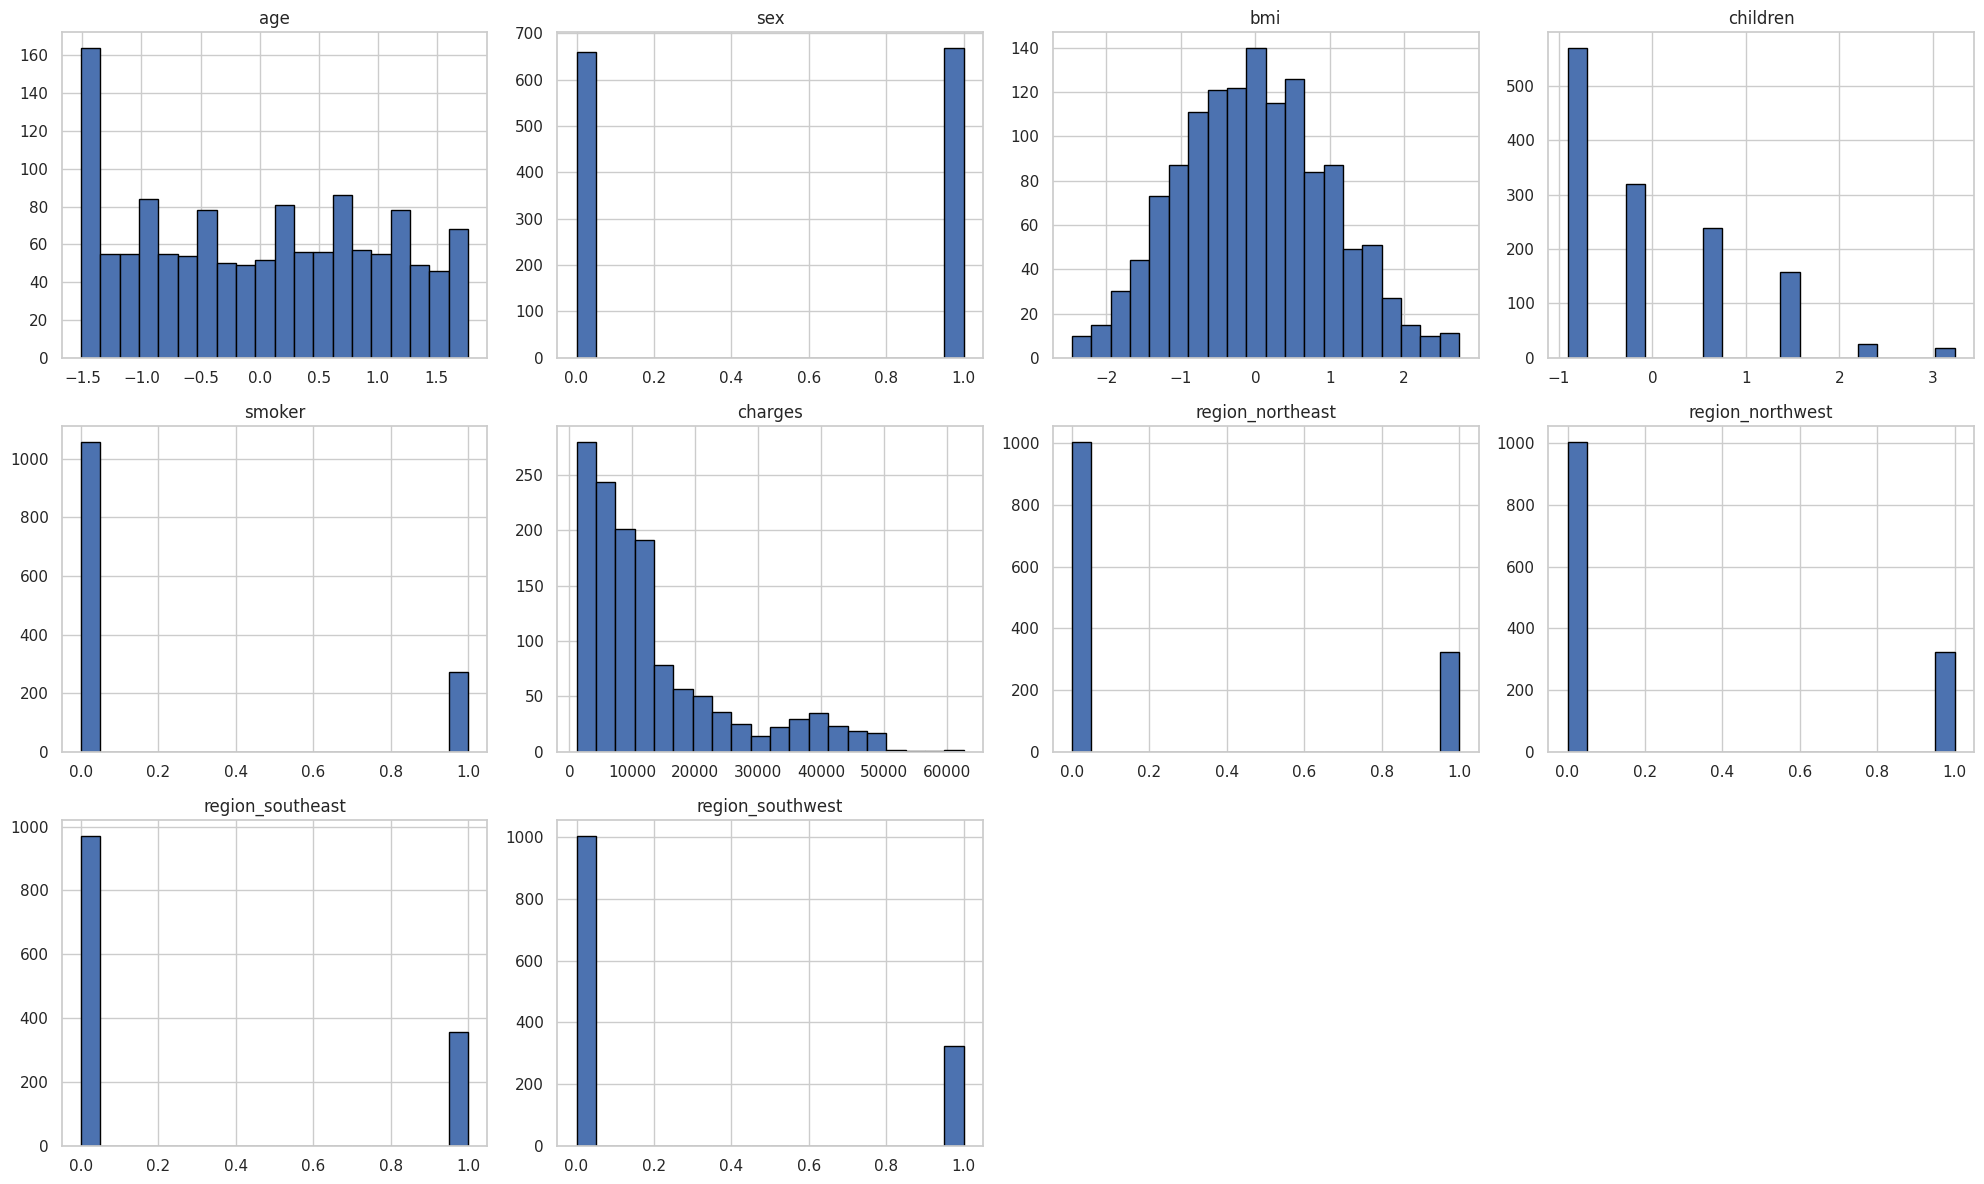

In [19]:
# Distribusi seluruh variabel pada data final
num_vars = df_final.shape[1]
n_cols = 4
n_rows = -(-num_vars // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = axes.flatten()
for i, column in enumerate(df_final.columns):
    df_final[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

### 5.2 Distribusi biaya asuransi (`charges`)
Distribusi `charges` condong ke kanan (right-skewed). Transformasi logaritma membuatnya lebih mendekati normal.

**Penjelasan.** Distribusi target `charges` digambar dua kali pada data bersih: dalam skala asli (kiri) dan setelah transformasi logaritma basis 10 (kanan). Parameter `kde=True` menambahkan kurva halus yang menggambarkan bentuk sebaran.

Grafik kiri condong ke kanan (*right-skewed*) karena sebagian besar biaya rendah dan hanya sedikit yang sangat tinggi. Setelah transformasi log, distribusi menjadi lebih simetris dan mendekati normal. Transformasi ini berguna sebagai ide perbaikan, walau pada praktikum ini target tetap dipakai dalam skala asli.

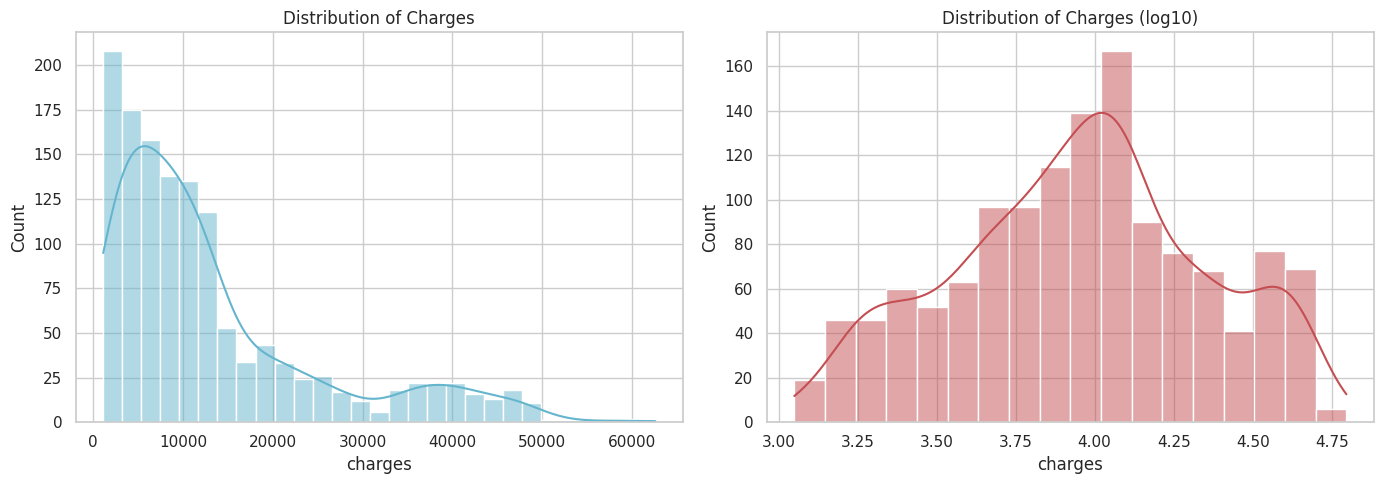

In [20]:
# Distribusi charges asli dan setelah transformasi log
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_clean['charges'], kde=True, color='c', ax=axes[0])
axes[0].set_title('Distribution of Charges')
sns.histplot(np.log10(df_clean['charges']), kde=True, color='r', ax=axes[1])
axes[1].set_title('Distribution of Charges (log10)')
plt.tight_layout()
plt.show()

### 5.3 Biaya asuransi berdasarkan wilayah dan faktor lain

**Penjelasan.** Data dikelompokkan berdasarkan `region` dengan `groupby`, lalu total `charges` dijumlahkan dan diurutkan dari yang terkecil. Hasilnya digambar sebagai diagram batang horizontal untuk membandingkan total biaya antarwilayah.

Total biaya tertinggi berada di wilayah southeast dan terendah di southwest. Perlu diingat bahwa total dipengaruhi jumlah pemegang polis di tiap wilayah, dan southeast memang memiliki pengamatan paling banyak.

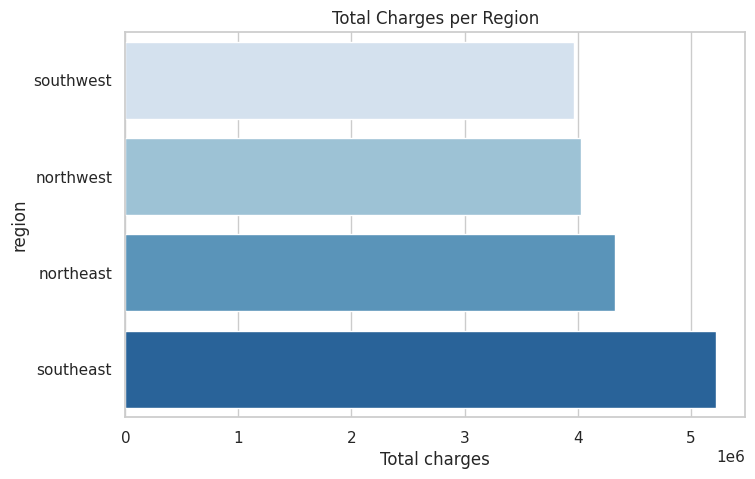

In [21]:
# Total biaya per wilayah
charges_region = df_clean.groupby('region')['charges'].sum().sort_values()
plt.figure(figsize=(8, 5))
sns.barplot(x=charges_region.values, y=charges_region.index,
            hue=charges_region.index, palette='Blues', legend=False)
plt.xlabel('Total charges')
plt.title('Total Charges per Region')
plt.show()

**Penjelasan.** Perulangan ini membuat tiga diagram batang yang menunjukkan rata-rata `charges` per wilayah, masing-masing dipisahkan berdasarkan `sex`, `smoker`, dan `children` melalui parameter `hue`. Pemisahan ini membantu melihat faktor mana yang benar-benar membedakan biaya di setiap wilayah.

Perbedaan antara perempuan dan laki-laki relatif kecil, pola berdasarkan jumlah anak tidak terlalu konsisten, tetapi perokok memiliki biaya yang jauh lebih tinggi di keempat wilayah.

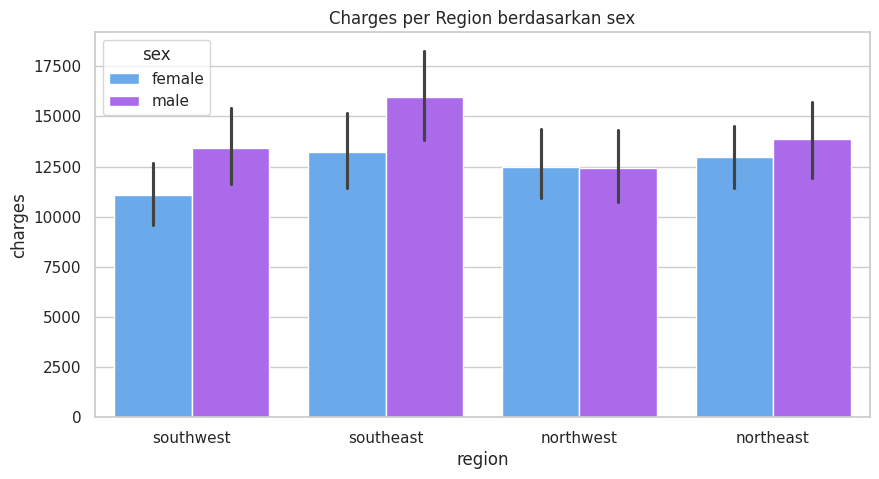

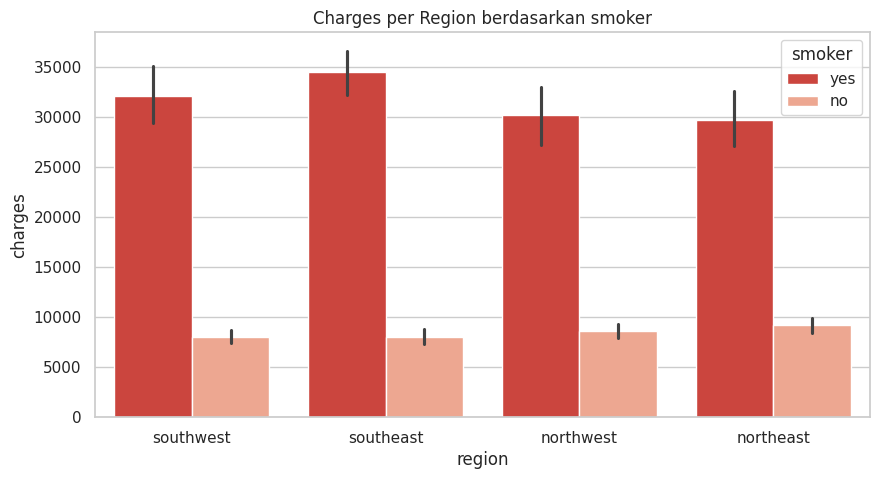

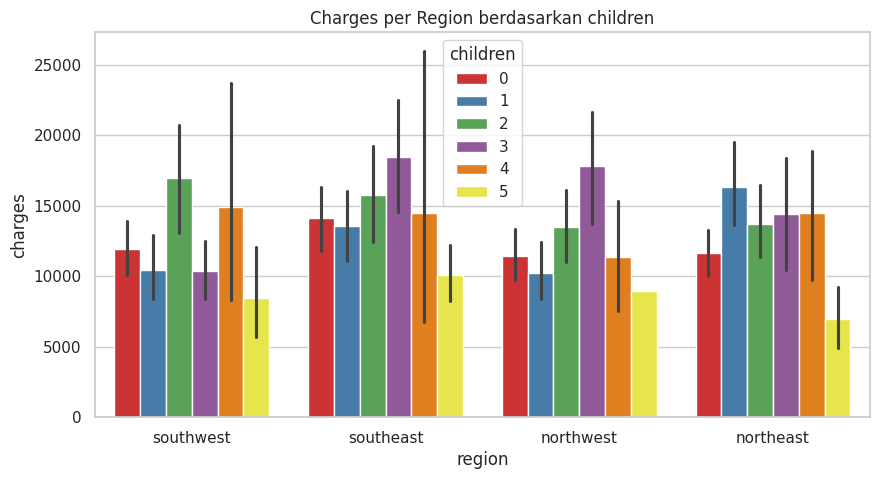

In [22]:
# Rata-rata charges per wilayah berdasarkan sex, smoker, dan children
for faktor, palet in [('sex', 'cool'), ('smoker', 'Reds_r'), ('children', 'Set1')]:
    plt.figure(figsize=(10, 5))
    sns.barplot(x='region', y='charges', hue=faktor, data=df_clean, palette=palet)
    plt.title(f'Charges per Region berdasarkan {faktor}')
    plt.show()

Wilayah Southeast memiliki total biaya tertinggi dan Southwest terendah. Perokok memiliki biaya yang jauh lebih tinggi di semua wilayah.

### 5.4 Biaya asuransi berdasarkan age, bmi, dan children (dipisah per perokok)

**Penjelasan.** Fungsi `lmplot` menggambar titik data beserta garis regresinya, dengan warna dibedakan berdasarkan status perokok. Tiga grafik dibuat untuk melihat hubungan `charges` dengan `age`, `bmi`, dan `children`.

Biaya naik seiring usia, dan terbentuk kelompok titik yang jelas dengan perokok berada paling atas. Pada `bmi`, bukan perokok hampir tidak terpengaruh, sedangkan pada perokok biaya naik tajam; ini menandakan adanya interaksi antara `smoker` dan `bmi`. Pengaruh `children` kecil.

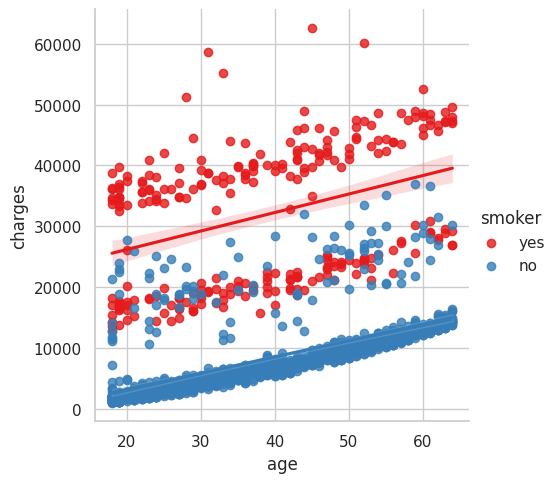

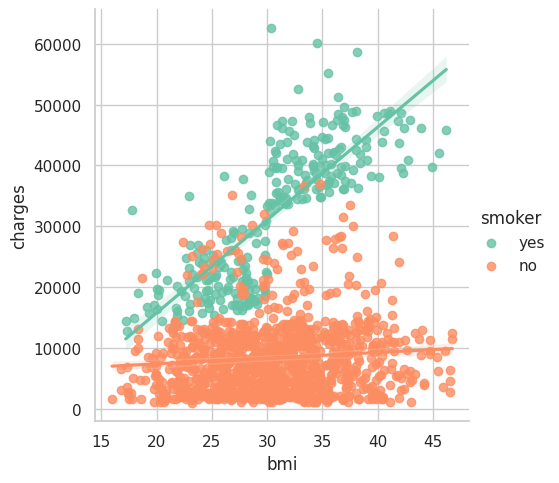

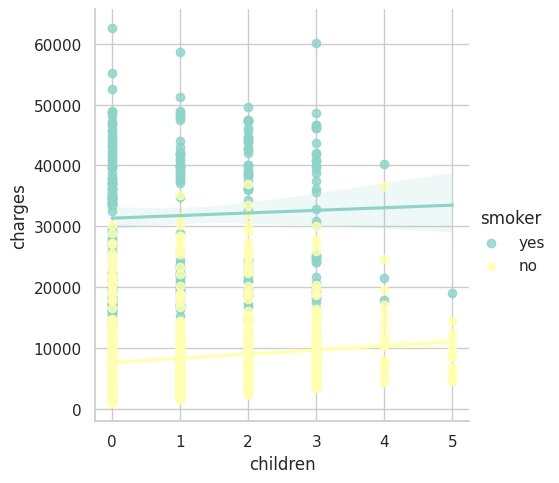

In [23]:
# Hubungan charges dengan age, bmi, children berdasarkan status perokok
sns.lmplot(x='age', y='charges', data=df_clean, hue='smoker', palette='Set1')
sns.lmplot(x='bmi', y='charges', data=df_clean, hue='smoker', palette='Set2')
sns.lmplot(x='children', y='charges', data=df_clean, hue='smoker', palette='Set3')
plt.show()

**Penjelasan.** Violin plot menampilkan sebaran `charges` untuk setiap jumlah anak, dipisahkan menurut status perokok. Bentuk lebar-sempitnya "biola" menunjukkan di rentang biaya mana kebanyakan data berkumpul.

Pada setiap jumlah anak, sebaran biaya perokok selalu berada jauh di atas bukan perokok, sedangkan jumlah anak sendiri tidak banyak mengubah pola. Ini menguatkan temuan bahwa merokok adalah faktor paling berpengaruh.

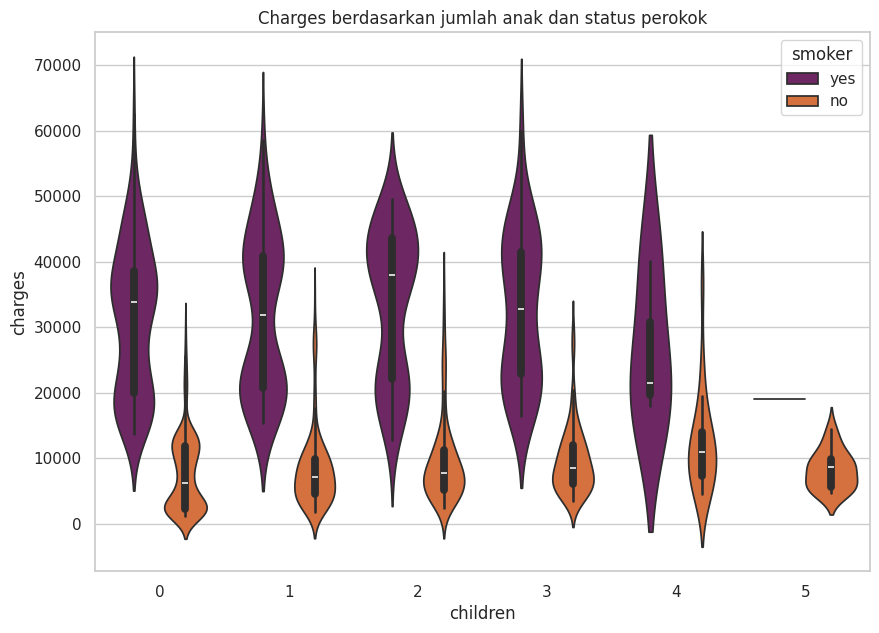

In [24]:
# Sebaran charges berdasarkan jumlah anak dan status perokok
plt.figure(figsize=(10, 7))
sns.violinplot(x='children', y='charges', data=df_clean,
               hue='smoker', palette='inferno')
plt.title('Charges berdasarkan jumlah anak dan status perokok')
plt.show()

Merokok adalah faktor yang paling berpengaruh pada biaya. Biaya juga cenderung naik seiring bertambahnya usia dan BMI.

### 5.5 Analisis korelasi
Matriks korelasi dibuat dari data final yang seluruh kolomnya sudah numerik.

**Penjelasan.** Matriks korelasi dihitung dengan `df_final.corr()` dan ditampilkan sebagai peta panas (*heatmap*). Setiap sel berisi koefisien korelasi Pearson antardua variabel dengan rentang −1 sampai +1; warna merah pekat berarti korelasi positif kuat dan biru berarti korelasi negatif kuat.

Dengan `annot=True` nilai korelasi tercetak pada tiap sel. Perhatikan baris atau kolom `charges`: hanya `smoker` yang tampak berkorelasi kuat, sedangkan variabel lain berkorelasi lemah. Kolom `region_*` saling berkorelasi negatif karena hanya satu wilayah yang bernilai 1 pada setiap baris.

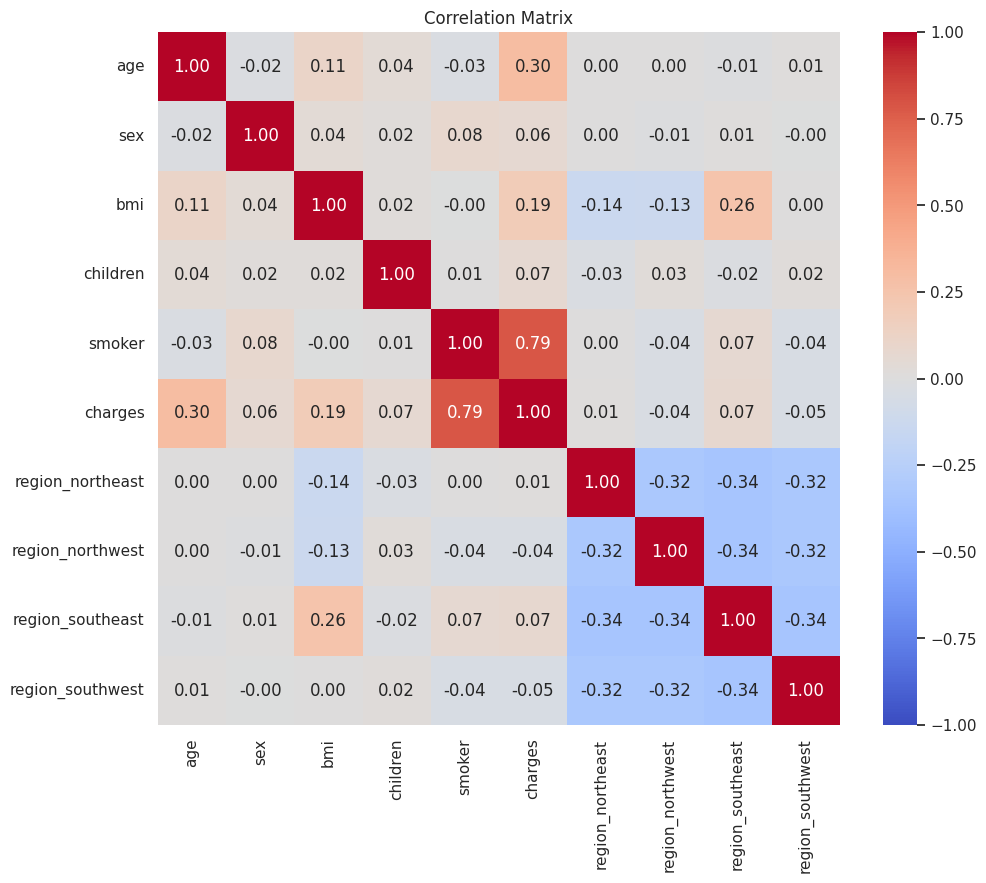

In [25]:
# Matriks korelasi antar variabel
plt.figure(figsize=(11, 9))
sns.heatmap(df_final.corr(), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

**Penjelasan.** Agar lebih fokus, korelasi dihitung khusus antara setiap fitur dan target `charges`. Nilainya diambil mutlak (`abs`) karena yang dilihat adalah kekuatan hubungan, bukan arahnya, lalu diurutkan dari yang terbesar dan digambar sebagai diagram batang.

Urutan teratas ditempati `smoker` (sekitar 0,79), diikuti `age` (sekitar 0,30) dan `bmi` (sekitar 0,19), sedangkan variabel lain sangat lemah. Informasi ini dapat dipakai untuk menyeleksi fitur, tetapi pada praktikum ini semua fitur tetap dipertahankan.

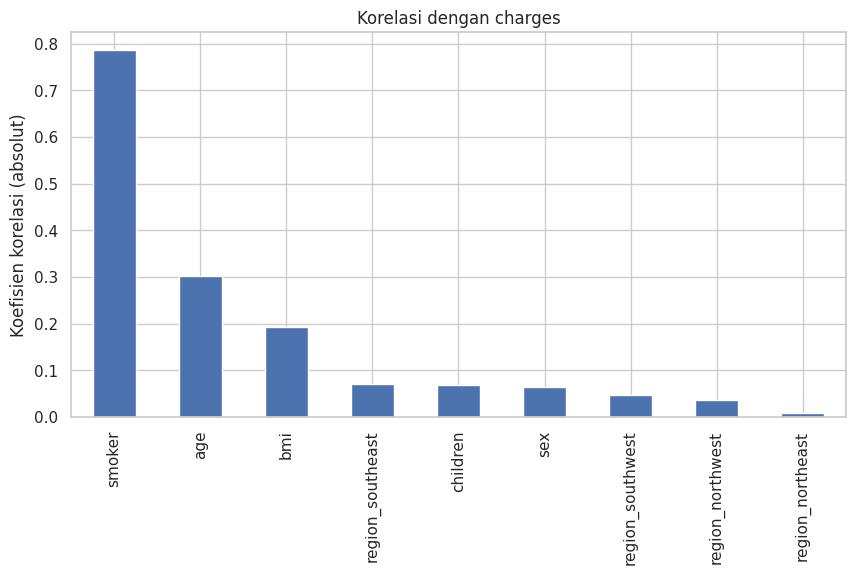

smoker              0.785896
age                 0.301317
bmi                 0.193270
region_southeast    0.071191
children            0.069125
sex                 0.064161
region_southwest    0.046341
region_northwest    0.036482
region_northeast    0.009342
Name: charges, dtype: float64

In [26]:
# Korelasi tiap variabel terhadap target (charges), diurutkan dari yang terkuat
corr_target = df_final.corr()['charges'].drop('charges').abs()
target_corr_sorted = corr_target.sort_values(ascending=False)

plt.figure(figsize=(10, 5))
target_corr_sorted.plot(kind='bar')
plt.title('Korelasi dengan charges')
plt.ylabel('Koefisien korelasi (absolut)')
plt.show()
target_corr_sorted

Variabel `smoker` memiliki korelasi paling kuat terhadap `charges`, disusul `age` dan `bmi`. Variabel `sex`, `children`, dan `region` berkorelasi lemah, tetapi semuanya tetap dipertahankan sebagai fitur.

## 6. Data Splitting
Data dipisah menjadi fitur (X) dan target (y), lalu dibagi 80% data latih dan 20% data uji.

**Penjelasan.** Data dipisah menjadi fitur `X` (semua kolom kecuali `charges`) dan target `y` (kolom `charges`). `train_test_split` kemudian membagi keduanya menjadi 80% data latih dan 20% data uji. Data latih dipakai untuk membangun model, sedangkan data uji disimpan untuk menilai kemampuan model pada data yang belum pernah dilihat.

Parameter `random_state=1` membuat pembagian acak selalu sama setiap notebook dijalankan sehingga hasil dapat direproduksi. Hasilnya 1.062 baris data latih dan 266 baris data uji, masing-masing dengan 9 fitur.

In [27]:
from sklearn.model_selection import train_test_split

# Pisahkan fitur (X) dan target (y)
X = df_final.drop(columns=['charges'])
y = df_final['charges']

# Bagi data: 80% latih, 20% uji
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1)
print("Data latih:", x_train.shape, "| Data uji:", x_test.shape)

Data latih: (1062, 9) | Data uji: (266, 9)


## 7. Pembangunan Model (Modelling)
Karena target berupa angka kontinu, model yang dipakai adalah algoritma **regresi**. Praktikum ini difokuskan pada dua model saja agar perbandingannya jelas: **Linear Regression** sebagai model dasar (baseline) yang sederhana, dan **Gradient Boosting Regressor** sebagai model yang lebih kompleks dan mampu menangkap hubungan non-linear.

**Penjelasan.** Dua model dilatih menggunakan data latih lewat `.fit(x_train, y_train)`. **Linear Regression** mencari persamaan garis lurus yang menghubungkan fitur dengan biaya dan menjadi model dasar sebagai pembanding. **Gradient Boosting Regressor** membangun banyak pohon keputusan secara berurutan, tiap pohon memperbaiki kesalahan pohon sebelumnya, sehingga mampu menangkap hubungan non-linear dan interaksi antarfitur.

Pemilihan dua model dengan karakter yang berbeda ini membuat perbandingan lebih bermakna: kita bisa melihat seberapa besar keuntungan model yang kompleks dibanding model sederhana. `random_state=184` memastikan hasil Gradient Boosting konsisten.

In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor

# Model 1: Linear Regression (model dasar / baseline)
LR = LinearRegression().fit(x_train, y_train)

# Model 2: Gradient Boosting Regressor (model non-linear berbasis pohon)
GBR = GradientBoostingRegressor(random_state=184).fit(x_train, y_train)

**Penjelasan.** Koefisien Linear Regression diambil dari `LR.coef_` dan disusun dalam tabel bersama nama fiturnya. Koefisien menunjukkan perubahan `charges` bila fitur tersebut naik satu satuan dengan fitur lain tetap; tandanya menunjukkan arah pengaruh (positif menaikkan biaya, negatif menurunkan). `intercept` adalah nilai dasar biaya ketika semua fitur bernilai nol.

Karena `age`, `bmi`, dan `children` sudah distandardisasi, koefisiennya menyatakan perubahan biaya untuk kenaikan satu simpangan baku. Koefisien `smoker` adalah yang terbesar, yaitu sekitar 23.391, sehingga perokok memiliki biaya jauh lebih tinggi; `age` dan `bmi` juga positif, sedangkan `sex` dan `region` kecil.

In [29]:
# Koefisien Linear Regression: tanda dan besarnya menunjukkan arah
# dan kekuatan pengaruh tiap fitur terhadap charges
koef = pd.DataFrame({'Koefisien': LR.coef_}, index=X.columns)
print("Intercept:", round(LR.intercept_, 2))
koef.round(2)

Intercept: 8518.61


,Koefisien
age,3557.36
sex,-176.94
bmi,1963.88
children,631.78
smoker,23391.20
region_northeast,437.72
region_northwest,195.08
region_southeast,-409.54
region_southwest,-223.26


## 8. Evaluasi Model
Setiap model dievaluasi pada data uji dengan MAE, MSE, RMSE, dan R². R² data latih juga ditampilkan untuk mengecek overfitting.

**Penjelasan.** Cell ini mengevaluasi kedua model. Kamus `prediksi` menyimpan prediksi tiap model pada data latih dan data uji, lalu perulangan menghitung empat metrik pada data uji: **MAE** (rata-rata selisih absolut), **MSE** (rata-rata kuadrat selisih), **RMSE** (akar MSE, satuannya sama dengan `charges`), dan **R²** (proporsi variasi biaya yang dapat dijelaskan model). R² data latih juga dihitung untuk memeriksa overfitting.

Hasil dikumpulkan dalam `df_results` dan diurutkan berdasarkan R² data uji. Semakin kecil MAE dan RMSE serta semakin besar R², semakin baik model. Jika R² latih jauh lebih tinggi daripada R² uji, model terindikasi overfitting.

In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prediksi kedua model pada data latih dan data uji
prediksi = {
    'Linear Regression': (LR.predict(x_train), LR.predict(x_test)),
    'Gradient Boosting': (GBR.predict(x_train), GBR.predict(x_test)),
}

# Kumpulkan metrik evaluasi ke dalam satu tabel
hasil = {}
for nama, (p_train, p_test) in prediksi.items():
    mse = mean_squared_error(y_test, p_test)
    hasil[nama] = {
        'MAE': mean_absolute_error(y_test, p_test),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R2 Test': r2_score(y_test, p_test),
        'R2 Train': r2_score(y_train, p_train),
    }

df_results = pd.DataFrame(hasil).T.sort_values('R2 Test', ascending=False)
df_results.round(4)

,MAE,MSE,RMSE,R2 Test,R2 Train
Gradient Boosting,2559.3938,2.033618e+07,4509.5653,0.8757,0.8994
Linear Regression,4355.3813,3.726764e+07,6104.7227,0.7723,0.7423


**Membaca hasil evaluasi.** Gradient Boosting menghasilkan R² data uji sekitar 0,88, MAE sekitar 2.559, dan RMSE sekitar 4.510, sedangkan Linear Regression hanya mencapai R² sekitar 0,77, MAE sekitar 4.355, dan RMSE sekitar 6.105. Artinya rata-rata kesalahan prediksi Gradient Boosting hampir separuh dari Linear Regression.

R² data latih Gradient Boosting (sekitar 0,90) tidak jauh dari R² data uji sehingga tidak ada indikasi overfitting. Linear Regression kalah karena mengasumsikan hubungan garis lurus, padahal efek merokok berinteraksi dengan BMI dan usia sehingga hubungan sebenarnya tidak linear.

**Penjelasan.** Diagram batang horizontal membandingkan R² data uji kedua model secara visual. Batang yang lebih panjang berarti model menjelaskan variasi biaya dengan lebih baik, sehingga perbedaan performa lebih cepat terbaca dibanding membaca angka pada tabel.

Gradient Boosting memiliki batang lebih panjang (R² sekitar 0,88) dibanding Linear Regression (R² sekitar 0,77). Kesimpulannya, model non-linear lebih sesuai untuk dataset ini.

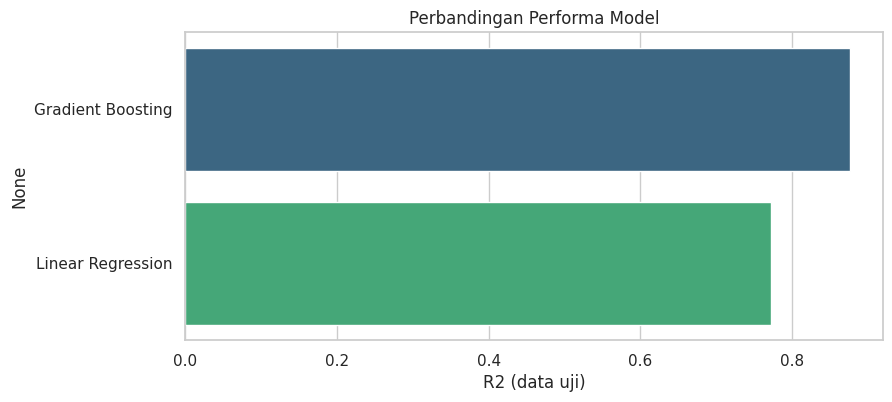

In [31]:
# Perbandingan R2 data uji antar model
plt.figure(figsize=(9, 4))
sns.barplot(x=df_results['R2 Test'], y=df_results.index,
            hue=df_results.index, palette='viridis', legend=False)
plt.xlabel('R2 (data uji)')
plt.title('Perbandingan Performa Model')
plt.show()

**Penjelasan.** Model berbasis pohon seperti Gradient Boosting menyediakan atribut `feature_importances_` yang menunjukkan seberapa besar kontribusi setiap fitur dalam menurunkan kesalahan prediksi. Nilainya dijadikan `Series`, diurutkan, lalu digambar sebagai diagram batang horizontal.

Fitur `smoker` mendominasi (sekitar 68%), disusul `bmi` (sekitar 18%) dan `age` (sekitar 12%), sedangkan fitur lain hampir tidak berpengaruh. Hasil ini sejalan dengan temuan pada analisis korelasi dan koefisien Linear Regression.

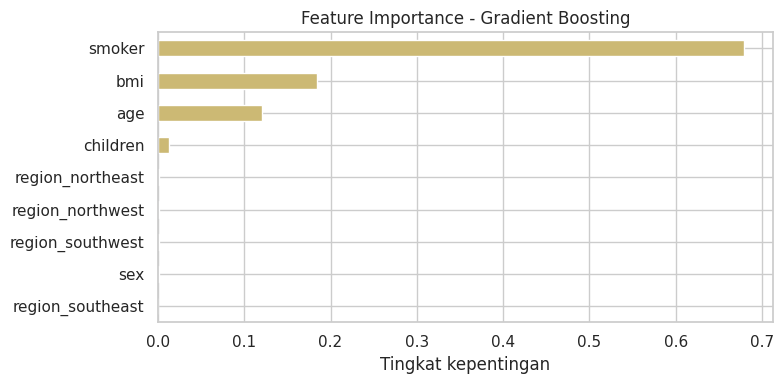

In [32]:
# Fitur terpenting menurut Gradient Boosting
imp = pd.Series(GBR.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 4))
imp.plot(kind='barh', color='y')
plt.title('Feature Importance - Gradient Boosting')
plt.xlabel('Tingkat kepentingan')
plt.tight_layout()
plt.show()

**Penjelasan.** Model terbaik dipilih otomatis dari baris pertama `df_results` (R² uji tertinggi), lalu **plot residual** dibuat. Residual adalah selisih antara nilai prediksi dan nilai aktual; titik abu-abu mewakili data latih dan titik biru mewakili data uji, sedangkan garis merah pada nilai nol adalah prediksi yang sempurna.

Model yang baik memiliki titik-titik yang tersebar di sekitar garis merah tanpa pola tertentu. Titik yang jauh dari garis, terutama dengan residual negatif besar, adalah kasus ketika biaya aktual jauh lebih tinggi daripada prediksi.

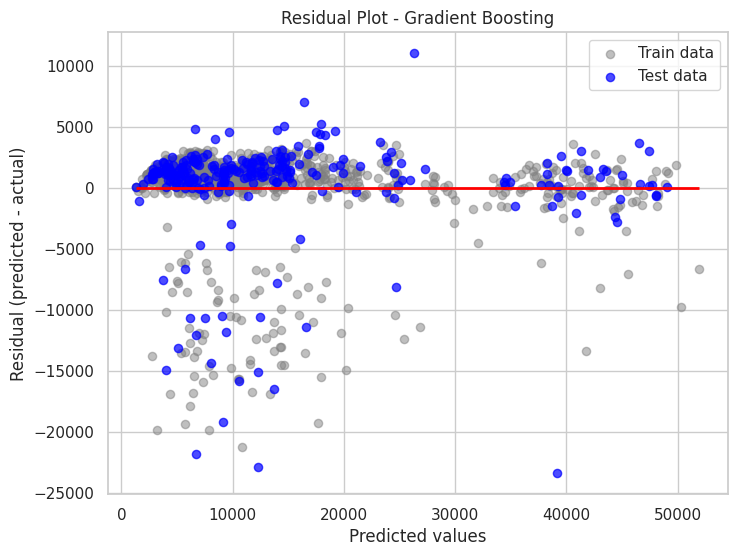

In [33]:
# Plot residual (prediksi - aktual) untuk model terbaik berdasarkan R2 uji
terbaik = df_results.index[0]
p_train, p_test = prediksi[terbaik]

plt.figure(figsize=(8, 6))
plt.scatter(p_train, p_train - y_train, c='gray', s=35, alpha=0.5,
            label='Train data')
plt.scatter(p_test, p_test - y_test, c='blue', s=35, alpha=0.7,
            label='Test data')
x_min = min(p_train.min(), p_test.min())
x_max = max(p_train.max(), p_test.max())
plt.hlines(y=0, xmin=x_min, xmax=x_max, colors='red', lw=2)
plt.xlabel('Predicted values')
plt.ylabel('Residual (predicted - actual)')
plt.title(f'Residual Plot - {terbaik}')
plt.legend()
plt.show()

**Penjelasan.** Tabel ini membandingkan nilai aktual dan nilai prediksi model terbaik pada data uji, ditambah kolom `Selisih` (prediksi dikurangi aktual). Dengan melihat contoh nyata, kita bisa menilai kualitas prediksi secara lebih konkret daripada hanya membaca angka metrik.

Pada sebagian besar baris prediksi mendekati nilai aktual, namun ada beberapa kasus yang meleset cukup jauh. Hal ini wajar karena masih ada faktor yang memengaruhi biaya tetapi tidak tercakup dalam dataset.

In [34]:
# Perbandingan nilai aktual dan prediksi pada data uji (model terbaik)
df_pred = pd.DataFrame({'Actual': y_test.values, 'Predicted': p_test}).round(2)
df_pred['Selisih'] = (df_pred['Predicted'] - df_pred['Actual']).round(2)
df_pred.head(10)

,Actual,Predicted,Selisih
0,21797.00,13973.78,-7823.22
1,1727.54,2964.59,1237.05
2,7418.52,7445.85,27.33
3,30260.00,13753.31,-16506.69
4,5124.19,7022.20,1898.01
5,41919.10,41338.75,-580.35
6,7650.77,7836.05,185.28
7,1743.21,2956.34,1213.13
8,2902.91,4404.37,1501.46
9,8410.05,9280.00,869.95


## 9. Penyimpanan Data dan Model
Dataset bersih dan model disimpan agar bisa dipakai kembali tanpa mengulang seluruh proses. Scaler ikut disimpan supaya data baru bisa distandardisasi dengan cara yang sama.

**Penjelasan.** Tahap penyimpanan (*data storage*) agar hasil kerja dapat dipakai kembali tanpa mengulang seluruh proses. Dataset final disimpan ke `insurance_clean.csv`, sedangkan model Gradient Boosting disimpan ke `gbr_model.joblib` menggunakan `joblib.dump`.

Selain model, `scaler` dan daftar kolom fitur ikut disimpan. Keduanya dibutuhkan saat memprediksi data baru: data baru harus distandardisasi dengan scaler yang sama dan kolomnya harus berurutan seperti saat pelatihan, kalau tidak hasil prediksi akan salah.

In [35]:
import joblib

# Simpan dataset final hasil pemrosesan
df_final.to_csv('insurance_clean.csv', index=False)

# Simpan model Gradient Boosting (seperti contoh dosen),
# scaler, dan urutan kolom fitur
joblib.dump(GBR, 'gbr_model.joblib')
joblib.dump(scaler, 'scaler.joblib')
joblib.dump(list(X.columns), 'fitur_kolom.joblib')
print("Tersimpan: insurance_clean.csv, gbr_model.joblib,",
      "scaler.joblib, fitur_kolom.joblib")

Tersimpan: insurance_clean.csv, gbr_model.joblib, scaler.joblib, fitur_kolom.joblib


## Kesimpulan
Faktor yang paling memengaruhi biaya asuransi adalah **status perokok (`smoker`)**, diikuti **usia (`age`)** dan **BMI (`bmi`)**. Dari dua model yang dibandingkan, **Gradient Boosting Regressor** memberikan performa terbaik pada data uji (R² sekitar 0,88 dan MAE sekitar 2.559) dibandingkan **Linear Regression** (R² sekitar 0,77 dan MAE sekitar 4.355), dengan selisih R² data latih dan data uji yang kecil sehingga tidak overfitting. Linear Regression tertinggal karena hubungan antara fitur dan biaya tidak sepenuhnya linear, terutama efek perokok yang berinteraksi dengan BMI dan usia, sedangkan Gradient Boosting mampu menangkap pola tersebut.